# Customer segmentation with K-Means (Mall Customers data)

This notebook groups 200 shoppers into segments with K-Means clustering and turns the segments into recommendations for a Kenyan retail chain.

**Data.** [Mall Customer Segmentation Data](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python) on Kaggle (Vijay Choudhary, from Udemy's Machine Learning A-Z course). The Kaggle page says the data set was "created only for the learning purpose", so it is not real Kenyan data. Each row is one member of a store loyalty card scheme with gender, age, annual income (thousands of US dollars) and a spending score from 1 to 100 that the store assigns from buying behaviour.

## 1. Setup
The libraries are loaded and a fixed random seed is set so the results repeat exactly.

In [1]:
import json, shutil, logging, warnings
warnings.filterwarnings('ignore', message='IProgress not found')          # progress-bar notice from tqdm
warnings.filterwarnings('ignore', message='PySpark does not yet fully support pandas')
warnings.filterwarnings('ignore', message='.*Arrow optimization.*')
logging.getLogger('kagglehub').setLevel(logging.WARNING)                   # hide the local cache path
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import kagglehub, sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.stats import chi2_contingency
SEED = 42
DATA, FIG = Path('data'), Path('figures')
DATA.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
# Okabe-Ito colours, a colour-blind safe set, always used in the same order
COLS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e6', 'grid.linewidth': 0.6})
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| kagglehub', kagglehub.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | kagglehub 1.0.3


## 2. Download the data from Kaggle
`kagglehub` downloads public Kaggle data sets without an account. The file (4 KB) is copied into `data/`.

In [2]:
src = Path(kagglehub.dataset_download('vjchoudhary7/customer-segmentation-tutorial-in-python')) / 'Mall_Customers.csv'
shutil.copy(src, DATA / 'Mall_Customers.csv')
df = pd.read_csv(DATA / 'Mall_Customers.csv').rename(columns={
    'Annual Income (k$)': 'income', 'Spending Score (1-100)': 'score', 'Gender': 'gender', 'Age': 'age', 'CustomerID': 'id'})
print(df.shape); df.head()

(200, 5)


,id,gender,age,income,score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 3. Check and explore the data
The data is checked for missing values and duplicates, and each column is summarised.

In [3]:
print('missing values:', int(df.isna().sum().sum()), '| duplicate rows:', int(df.duplicated().sum()))
print(df.gender.value_counts().to_dict())
print(df[['age', 'income', 'score']].describe().round(1))
print('\ncorrelations'); print(df[['age', 'income', 'score']].corr().round(2))

missing values: 0 | duplicate rows: 0
{'Female': 112, 'Male': 88}
         age  income  score
count  200.0   200.0  200.0
mean    38.8    60.6   50.2
std     14.0    26.3   25.8
min     18.0    15.0    1.0
25%     28.8    41.5   34.8
50%     36.0    61.5   50.0
75%     49.0    78.0   73.0
max     70.0   137.0   99.0

correlations
         age  income  score
age     1.00   -0.01  -0.33
income -0.01    1.00   0.01
score  -0.33    0.01   1.00


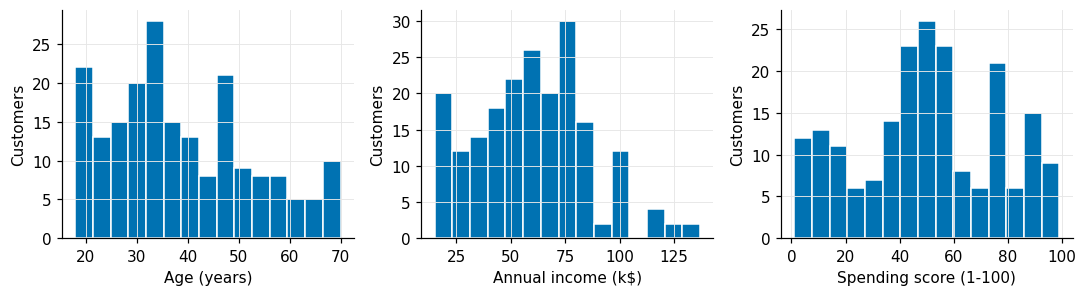

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, col, lab in zip(axes, ['age', 'income', 'score'], ['Age (years)', 'Annual income (k$)', 'Spending score (1-100)']):
    ax.hist(df[col], bins=15, color=COLS[0], edgecolor='white', linewidth=1)
    ax.set_xlabel(lab); ax.set_ylabel('Customers')
plt.tight_layout(); plt.savefig(FIG / 'distributions.png', bbox_inches='tight'); plt.show()

## 4. Choose the features
Income and spending score are used for the main model. They describe what a customer can spend and what the customer actually spends, which is what a marketing team acts on. Gender is left out on purpose so that segments are not built on a protected trait. Age is added later as a check.

Both features are put on the same scale (mean 0, standard deviation 1) so that neither one dominates the distances.

In [5]:
FEATS = ['income', 'score']
X = StandardScaler().fit_transform(df[FEATS])
X3 = StandardScaler().fit_transform(df[['age', 'income', 'score']])

## 5. Choose the number of clusters
K-Means is run for k = 2 to 10. Four signals are compared.
- **Inertia** (elbow): total squared distance to the nearest centre. Lower is tighter.
- **Silhouette**: how much closer each point is to its own cluster than to the next one. Higher is better (max 1).
- **Davies-Bouldin**: lower is better. **Calinski-Harabasz**: higher is better.
- **Stability**: K-Means is refitted on 50 random 90 % samples and compared with the full-data labels by the adjusted Rand index (1 = identical).

In [6]:
def km(k, seed=SEED):
    return KMeans(n_clusters=k, n_init=20, random_state=seed)
rng = np.random.default_rng(SEED)
def stability(Xm, k, n=50):
    full = km(k).fit_predict(Xm); s = []
    for i in range(n):
        idx = rng.choice(len(Xm), int(0.9 * len(Xm)), replace=False)
        s.append(adjusted_rand_score(full[idx], km(k, SEED + i + 1).fit(Xm[idx]).predict(Xm[idx])))
    return float(np.mean(s))
rows = []
for k in range(1, 11):
    m = km(k).fit(X); r = {'k': k, 'inertia': m.inertia_}
    if k > 1:
        r.update(silhouette=silhouette_score(X, m.labels_), davies_bouldin=davies_bouldin_score(X, m.labels_),
                 calinski_harabasz=calinski_harabasz_score(X, m.labels_), stability=stability(X, k))
    rows.append(r)
ksel = pd.DataFrame(rows).set_index('k')
print(ksel.round(3))

    inertia  silhouette  davies_bouldin  calinski_harabasz  stability
k                                                                    
1   400.000         NaN             NaN                NaN        NaN
2   269.691       0.321           1.267             95.669      0.379
3   157.704       0.467           0.716            151.335      1.000
4   108.921       0.494           0.710            174.595      0.809
5    65.568       0.555           0.572            248.649      0.992
6    55.057       0.540           0.655            243.088      0.951
7    44.865       0.528           0.715            254.621      0.930
8    37.148       0.457           0.758            267.914      0.925
9    32.392       0.457           0.763            270.948      0.940
10   29.686       0.436           0.765            263.350      0.737


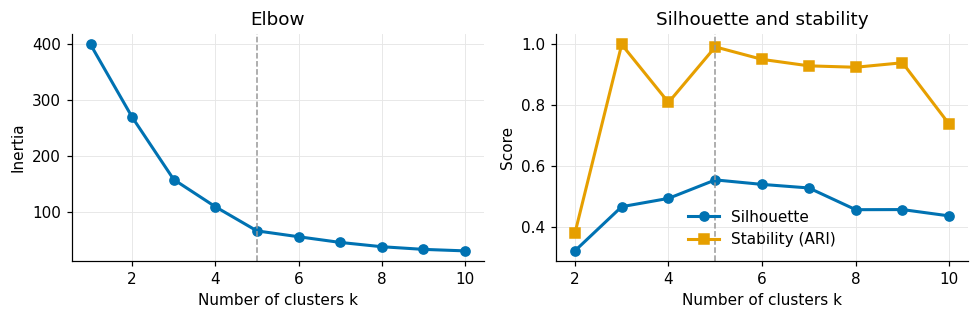

k with the highest silhouette: 5


In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3))
a1.plot(ksel.index, ksel.inertia, marker='o', color=COLS[0], lw=2, ms=6)
a1.set_xlabel('Number of clusters k'); a1.set_ylabel('Inertia'); a1.set_title('Elbow')
a2.plot(ksel.index[1:], ksel.silhouette[1:], marker='o', color=COLS[0], lw=2, ms=6, label='Silhouette')
a2.plot(ksel.index[1:], ksel.stability[1:], marker='s', color=COLS[1], lw=2, ms=6, label='Stability (ARI)')
a2.set_xlabel('Number of clusters k'); a2.set_ylabel('Score'); a2.set_title('Silhouette and stability'); a2.legend(frameon=False)
for a in (a1, a2): a.axvline(5, color='#999999', ls='--', lw=1)
plt.tight_layout(); plt.savefig(FIG / 'k_selection.png', bbox_inches='tight'); plt.show()
K = int(ksel.silhouette.idxmax()); print('k with the highest silhouette:', K)

## 6. Fit the final model
K-Means is fitted with the chosen k. The clusters are named from their average income and spending score.

In [8]:
model = km(K).fit(X)
df['cluster'] = model.labels_
prof = df.groupby('cluster').agg(customers=('id', 'size'), age=('age', 'mean'), income=('income', 'mean'),
                                 score=('score', 'mean'), female_pct=('gender', lambda g: 100 * (g == 'Female').mean()))
mi, ms = df.income.mean(), df.score.mean()
def name(r):
    inc = 'High' if r.income > mi + 15 else 'Low' if r.income < mi - 15 else 'Middle'
    spd = 'high' if r.score > ms + 15 else 'low' if r.score < ms - 15 else 'middle'
    return {'High high': 'Premium spenders', 'High low': 'Careful high earners', 'Middle middle': 'Core shoppers',
            'Low high': 'Young enthusiasts', 'Low low': 'Budget shoppers'}.get(f'{inc} {spd}', f'{inc} income, {spd} spend')
prof['segment'] = prof.apply(name, axis=1)
assert prof.segment.is_unique, prof
df['segment'] = df.cluster.map(prof.segment)
WANT = ['Premium spenders', 'Careful high earners', 'Core shoppers', 'Young enthusiasts', 'Budget shoppers']
ORDER = [s for s in WANT if s in set(prof.segment)] + [s for s in prof.segment if s not in WANT]
prof = prof.set_index('segment').loc[ORDER]
COLOR = {s: COLS[i] for i, s in enumerate(ORDER)}
print(prof.round(1))

                      customers   age  income  score  female_pct
segment                                                         
Premium spenders             39  32.7    86.5   82.1        53.8
Careful high earners         35  41.1    88.2   17.1        45.7
Core shoppers                81  42.7    55.3   49.5        59.3
Young enthusiasts            22  25.3    25.7   79.4        59.1
Budget shoppers              23  45.2    26.3   20.9        60.9


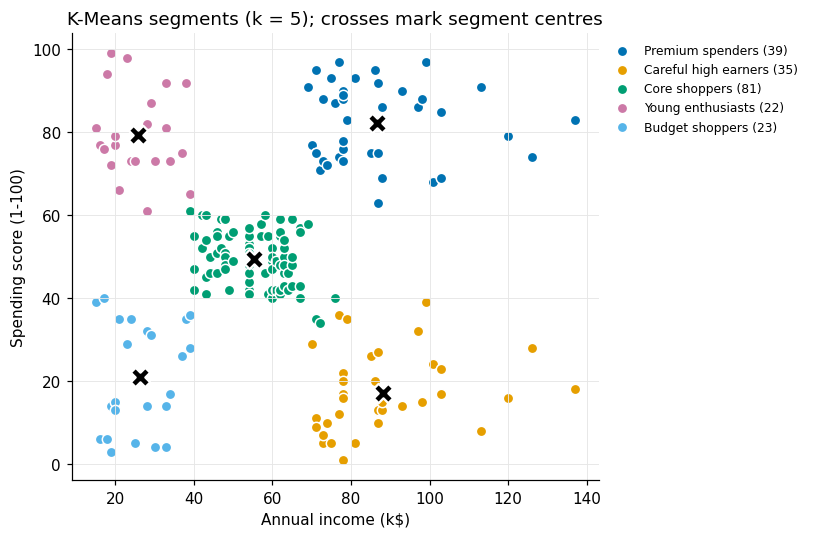

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for s in ORDER:
    g = df[df.segment == s]
    ax.scatter(g.income, g.score, s=46, color=COLOR[s], edgecolor='white', linewidth=1, label=f'{s} ({len(g)})')
cent = df.groupby('segment')[['income', 'score']].mean()
for s, r in cent.iterrows():
    ax.scatter(r.income, r.score, marker='X', s=160, color='black', edgecolor='white', linewidth=1.5, zorder=3)
ax.set_xlabel('Annual income (k$)'); ax.set_ylabel('Spending score (1-100)')
ax.set_title(f'K-Means segments (k = {K}); crosses mark segment centres')
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.tight_layout(); plt.savefig(FIG / 'segments.png', bbox_inches='tight'); plt.show()

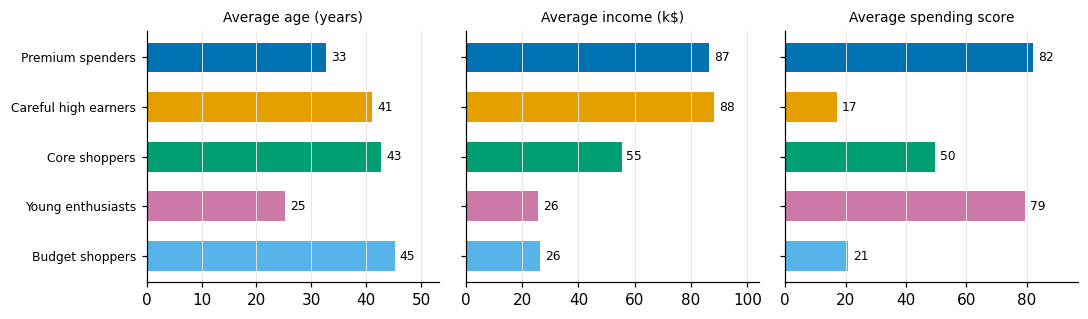

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, col, lab in zip(axes, ['age', 'income', 'score'], ['Average age (years)', 'Average income (k$)', 'Average spending score']):
    v = prof[col]
    ax.barh(range(len(v)), v.values, color=[COLOR[s] for s in v.index], height=0.6)
    ax.set_yticks(range(len(v)), v.index if ax is axes[0] else [''] * len(v), fontsize=8); ax.invert_yaxis()
    for i, x in enumerate(v.values): ax.text(x + v.max() * 0.02, i, f'{x:.0f}', va='center', fontsize=8)
    ax.set_title(lab, fontsize=9); ax.grid(axis='y', visible=False); ax.set_xlim(0, v.max() * 1.18)
plt.tight_layout(); plt.savefig(FIG / 'profiles.png', bbox_inches='tight'); plt.show()

## 7. Check the result
Three checks are made.
1. **Another algorithm.** Agglomerative (Ward) clustering with the same k is compared by the adjusted Rand index.
2. **Gender.** A chi-square test shows whether the share of women differs between segments. If it does not, leaving gender out lost nothing.
3. **Age.** K-Means is refitted with age as a third feature to see what changes.

In [11]:
ward = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(X)
ari_ward = adjusted_rand_score(df.cluster, ward)
chi2, p_gender, dof, _ = chi2_contingency(pd.crosstab(df.cluster, df.gender))
sil3 = {k: silhouette_score(X3, km(k).fit_predict(X3)) for k in range(2, 11)}
K3 = max(sil3, key=sil3.get)
df['cluster3'] = km(K3).fit_predict(X3)
ari_3 = adjusted_rand_score(df.cluster, df.cluster3)
print(f'Ward vs K-Means ARI = {ari_ward:.3f}')
print(f'Gender vs segment chi-square = {chi2:.2f}, dof = {dof}, p = {p_gender:.3f}')
print('With age: silhouette by k', {k: round(v, 3) for k, v in sil3.items()}, '| best k =', K3, f'| ARI with 2-feature model = {ari_3:.3f}')
print(pd.crosstab(df.segment, df.cluster3).loc[ORDER])
print(df.groupby('cluster3')[['age', 'income', 'score']].mean().round(1).assign(n=df.cluster3.value_counts().sort_index()))

Ward vs K-Means ARI = 0.942
Gender vs segment chi-square = 2.23, dof = 4, p = 0.693
With age: silhouette by k {2: 0.335, 3: 0.358, 4: 0.404, 5: 0.417, 6: 0.427, 7: 0.417, 8: 0.409, 9: 0.42, 10: 0.397} | best k = 6 | ARI with 2-feature model = 0.691
cluster3               0   1   2   3   4   5
segment                                     
Premium spenders       0   0   0  39   0   0
Careful high earners  32   1   0   0   2   0
Core shoppers          1  43   1   0  36   0
Young enthusiasts      0   0  22   0   0   0
Budget shoppers        0   1   1   0   0  21
           age  income  score   n
cluster3                         
0         41.9    88.9   17.0  33
1         56.3    54.3   49.1  45
2         25.2    25.8   76.9  24
3         32.7    86.5   82.1  39
4         26.7    57.6   47.8  38
5         45.5    26.3   19.4  21


## 8. The same model in Apache Spark
A real retail chain would have millions of till records, which is too much for one machine. Spark MLlib runs K-Means across a cluster. Here it runs in local mode on the same two scaled features, and its labels are compared with scikit-learn's. The step is skipped if PySpark or Java is missing.

In [12]:
ari_spark = None
try:
    from pyspark.sql import SparkSession
    from pyspark.ml.feature import VectorAssembler, StandardScaler as SparkScaler
    from pyspark.ml.clustering import KMeans as SparkKMeans
    spark = SparkSession.builder.master('local[*]').appName('segments').config('spark.ui.enabled', 'false').getOrCreate()
    spark.sparkContext.setLogLevel('ERROR')
    sdf = spark.createDataFrame(df[['id', 'income', 'score']].astype(float))
    sdf = VectorAssembler(inputCols=FEATS, outputCol='raw').transform(sdf)
    sdf = SparkScaler(inputCol='raw', outputCol='features', withMean=True, withStd=True).fit(sdf).transform(sdf)
    fits = [SparkKMeans(k=K, seed=s, featuresCol='features').fit(sdf) for s in range(10)]
    best = min(fits, key=lambda m: m.summary.trainingCost)   # keep the best of 10 starts, like n_init
    pred = {int(r.id): r.prediction for r in best.transform(sdf).select('id', 'prediction').collect()}
    ari_spark = adjusted_rand_score(df.cluster, df.id.map(pred))
    print('Spark', spark.version, f'| K-Means k = {K} | ARI with scikit-learn = {ari_spark:.3f}')
    spark.stop()
except Exception as e:
    print('Spark step skipped:', type(e).__name__, str(e)[:120])

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/27 12:51:58 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0 | K-Means k = 5 | ARI with scikit-learn = 1.000


## 9. Save the results
The main numbers are written to `results_segmentation.json` so the report can quote them exactly.

In [13]:
out = {'n_customers': int(len(df)), 'female': int((df.gender == 'Female').sum()), 'features': FEATS, 'k': K,
       'k_selection': ksel.round(4).reset_index().to_dict('records'),
       'final': {'silhouette': round(float(silhouette_score(X, df.cluster)), 4), 'davies_bouldin': round(float(davies_bouldin_score(X, df.cluster)), 4),
                 'calinski_harabasz': round(float(calinski_harabasz_score(X, df.cluster)), 1), 'stability': round(float(ksel.loc[K, 'stability']), 4)},
       'profiles': prof.round(1).reset_index().to_dict('records'),
       'ari_ward': round(float(ari_ward), 4), 'gender_chi2': round(float(chi2), 3), 'gender_p': round(float(p_gender), 4),
       'k_with_age': int(K3), 'silhouette_with_age': {int(k): round(float(v), 4) for k, v in sil3.items()}, 'ari_with_age': round(float(ari_3), 4), 'ari_spark': None if ari_spark is None else round(float(ari_spark), 4),
       'with_age_profiles': df.groupby('cluster3')[['age', 'income', 'score']].mean().round(1).assign(n=df.cluster3.value_counts().sort_index()).reset_index().to_dict('records'),
       'corr': df[['age', 'income', 'score']].corr().round(3).to_dict()}
Path('results_segmentation.json').write_text(json.dumps(out, indent=2, default=float))
df.to_csv(DATA / 'mall_customers_segments.csv', index=False)
print(json.dumps({k: out[k] for k in ['n_customers', 'k', 'final', 'ari_ward', 'gender_p', 'k_with_age', 'ari_with_age']}))

{"n_customers": 200, "k": 5, "final": {"silhouette": 0.5547, "davies_bouldin": 0.5722, "calinski_harabasz": 248.6, "stability": 0.9921}, "ari_ward": 0.942, "gender_p": 0.6932, "k_with_age": 6, "ari_with_age": 0.6915}
